In [1]:
import os
import numpy as np, pandas as pd, seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

DATA = 'data/'
df_customers    = pd.read_csv(DATA + 'finmark_cleaned_customers.csv')
df_transactions = pd.read_csv(DATA + 'finmark_cleaned_transactions.csv')
df_interactions = pd.read_csv(DATA + 'finmark_cleaned_interactions.csv')
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid', font_scale=1.0)
print(df_customers.shape, df_transactions.shape, df_interactions.shape)

(3000, 7) (3000, 7) (3000, 6)


In [2]:
# Numerical summaries (pandas std/var use ddof=1, same as Milestone 1)
for name, s in [('Age', df_customers['Age']), ('Amount', df_transactions['Amount'])]:
    print(f"{name}: mean={s.mean():.2f} median={s.median():.2f} mode={s.mode()[0]:.2f} "
          f"std={s.std():.2f} var={s.var():.2f} min={s.min():.2f} max={s.max():.2f}")

amt = df_transactions['Amount']
print('\nSpikes in Amount -> median-filled:', (amt == amt.median()).sum(), '| exactly 0:', (amt == 0).sum(), '| exactly 100:', (amt == 100).sum())
print('Age == 45 (median-filled mode):', (df_customers['Age'] == 45).sum())
print('\nRemaining nulls:', df_customers.isna().sum()[lambda x: x>0].to_dict(), df_transactions.isna().sum()[lambda x: x>0].to_dict(), df_interactions.isna().sum()[lambda x: x>0].to_dict())
print('Rows vs unique IDs:', len(df_customers), df_customers.CustomerID.nunique(), '|', len(df_transactions), df_transactions.TransactionID.nunique(), '|', len(df_interactions), df_interactions.InteractionID.nunique())

Age: mean=44.68 median=45.00 mode=45.00 std=14.44 var=208.43 min=18.00 max=70.00
Amount: mean=488.89 median=491.65 mode=491.65 std=282.46 var=79781.15 min=0.00 max=999.86

Spikes in Amount -> median-filled: 282 | exactly 0: 58 | exactly 100: 34
Age == 45 (median-filled mode): 422

Remaining nulls: {} {} {}
Rows vs unique IDs: 3000 3000 | 3000 3000 | 3000 3000


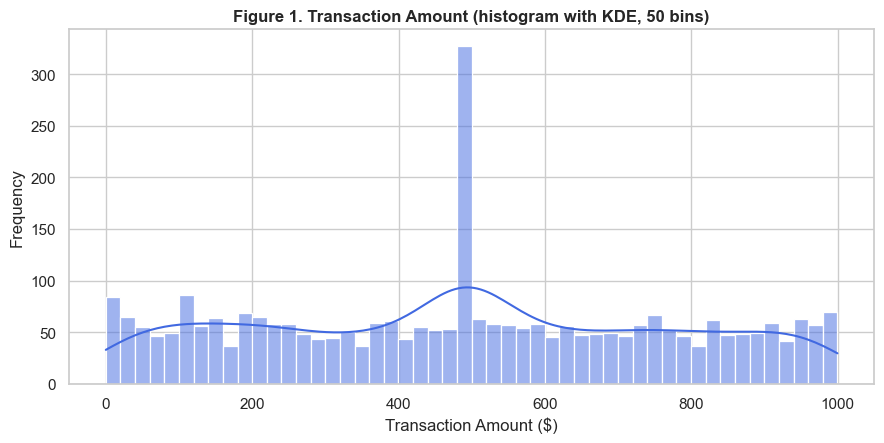

In [3]:
# Figure 1: histogram + KDE
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.histplot(df_transactions['Amount'], bins=50, kde=True, color='royalblue', ax=ax)
ax.set_title('Figure 1. Transaction Amount (histogram with KDE, 50 bins)', weight='bold')
ax.set_xlabel('Transaction Amount ($)'); ax.set_ylabel('Frequency')
plt.tight_layout(); plt.savefig('figures/fig1_amount_hist.png', dpi=170); plt.show()

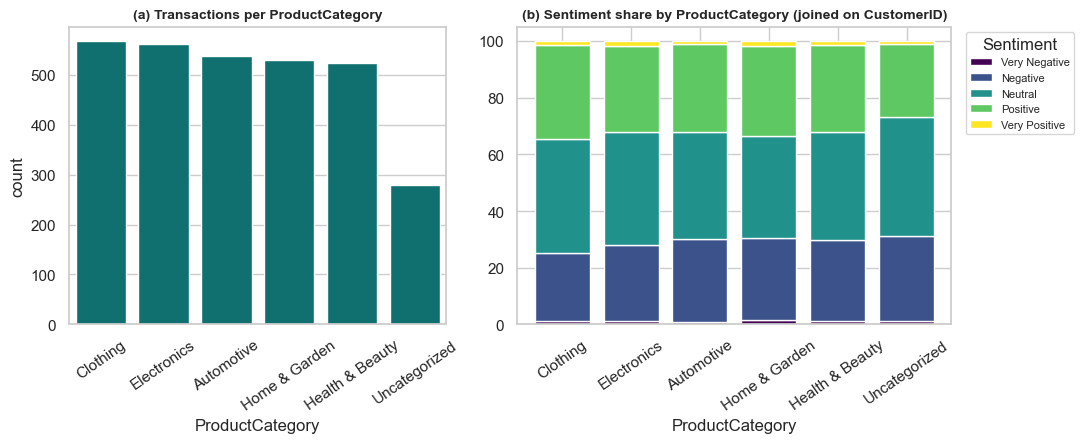

Sentiment        Negative  Neutral  Positive  Very Negative  Very Positive
ProductCategory                                                           
Automotive           29.4     37.8      31.0            0.9            1.0
Clothing             24.1     40.1      33.2            1.1            1.5
Electronics          27.1     39.6      30.4            1.1            1.8
Health & Beauty      28.5     38.1      30.7            1.4            1.4
Home & Garden        29.0     35.9      31.9            1.6            1.6
Uncategorized        30.2     42.0      25.6            1.1            1.1
chi-square p = 0.88, Cramer V = 0.03


In [4]:
# Figure 2: (a) counts per ProductCategory, (b) sentiment share, joined on CustomerID
order = df_transactions['ProductCategory'].value_counts().index
linked = df_transactions.merge(df_interactions[['CustomerID', 'Sentiment']], on='CustomerID')
ct = pd.crosstab(linked['ProductCategory'], linked['Sentiment'])
share = ct.div(ct.sum(axis=1), axis=0) * 100
cols = ['Very Negative', 'Negative', 'Neutral', 'Positive', 'Very Positive']

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={'width_ratios': [1, 1.15]})
sns.countplot(data=df_transactions, x='ProductCategory', order=order, color='teal', ax=ax[0])
ax[0].set_title('(a) Transactions per ProductCategory', weight='bold', fontsize=10); ax[0].tick_params(axis='x', rotation=35)
share.loc[order, cols].plot(kind='bar', stacked=True, ax=ax[1], colormap='viridis', width=0.8)
ax[1].set_title('(b) Sentiment share by ProductCategory (joined on CustomerID)', weight='bold', fontsize=10)
ax[1].legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8); ax[1].tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.savefig('figures/fig2_category_sentiment.png', dpi=170); plt.show()

chi2, p, _, _ = chi2_contingency(ct)
print(share.round(1)); print(f'chi-square p = {p:.2f}, Cramer V = {np.sqrt(chi2/ct.values.sum()/(min(ct.shape)-1)):.2f}')

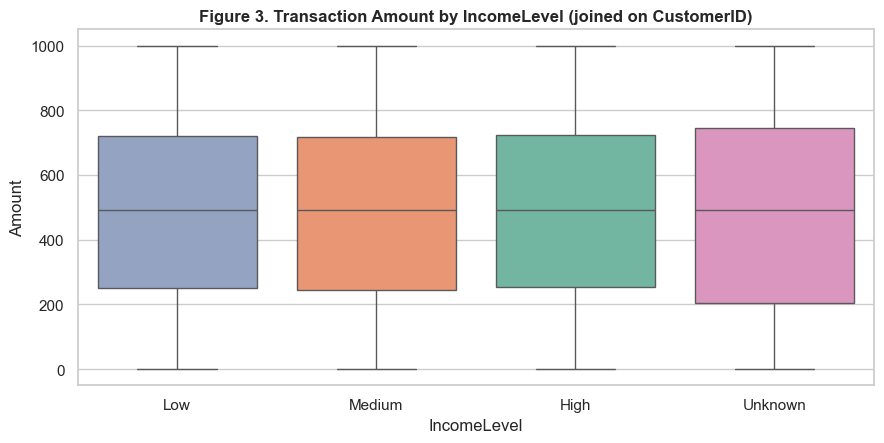

              mean    25%    50%    75%
IncomeLevel                            
High         489.0  254.4  491.6  722.1
Low          492.4  249.5  491.6  720.4
Medium       485.3  244.0  491.6  716.7
Unknown      488.6  204.8  491.6  745.2


In [5]:
# Figure 3: Amount by IncomeLevel, joined on CustomerID
merged = df_transactions.merge(df_customers.drop_duplicates('CustomerID')[['CustomerID', 'IncomeLevel']], on='CustomerID', how='left')
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.boxplot(data=merged, x='IncomeLevel', y='Amount', order=['Low', 'Medium', 'High', 'Unknown'], hue='IncomeLevel', palette='Set2', legend=False, ax=ax)
ax.set_title('Figure 3. Transaction Amount by IncomeLevel (joined on CustomerID)', weight='bold')
plt.tight_layout(); plt.savefig('figures/fig3_amount_by_income.png', dpi=170); plt.show()
print(merged.groupby('IncomeLevel')['Amount'].describe()[['mean', '25%', '50%', '75%']].round(1))